In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [4]:
work_folder = 'edge_spen'
saving_folder = 'l9'
os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [6]:
vision=state_dim[-1]
from ppo_ants import *

In [7]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad)

    return env, ppo_ants

In [8]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

In [9]:
load_from_run = True
ppo_ants.setup_networks()
best_weigths = False

if load_from_run and best_weigths:
    ppo_ants.load_weights(saving_folder + '/weights/best_weights')
else:
    if load_from_run:
        ppo_ants.load_weights(saving_folder + '/weights')
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/critic_weights_ang2907.pth", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/actor_weights_ang2907.pth", weights_only=True))

In [10]:
save_model = False

if save_model:
    torch.save(ppo_ants.critic.state_dict(), f"{saving_folder}/critic_weights.pth")
    torch.save(ppo_ants.actor.state_dict(), f"{saving_folder}/actor_weights.pth")

In [11]:
print(ppo_ants.critic)

CNN_critic(
  (cnn_layers): Sequential(
    (0): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=valid)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=valid)
    (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.0, inplace=False)
  )
  (fc_layers): Sequential(
    (0): Linear(in_features=400, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.0, inplace=False)
  )
  (output_layer): Linear(in_features=128, out_features=1, bias=True)
)


In [12]:
#n_special = int(20*n/100)
print(f"Number of special ants: {n_special}")

ppo_ants.env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

ppo_ants.env.reset_objects()
ppo_ants.env.delta[:] = 0.6
ppo_ants.env.beta[:] = 7.5
ppo_ants.env.transient()
trans_pos = ppo_ants.env.positions.copy()
trans_pher = ppo_ants.env.pheromones.copy()

results = ppo_ants.test_episode(max_prob=False, save_pos = True, reset=False)
print('delta=', ppo_ants.env.delta[0], 'beta=', ppo_ants.env.beta[0])

Number of special ants: 30
delta= 0.6 beta= 7.5


In [13]:
print(np.mean(results[0]))

-0.581710902958764


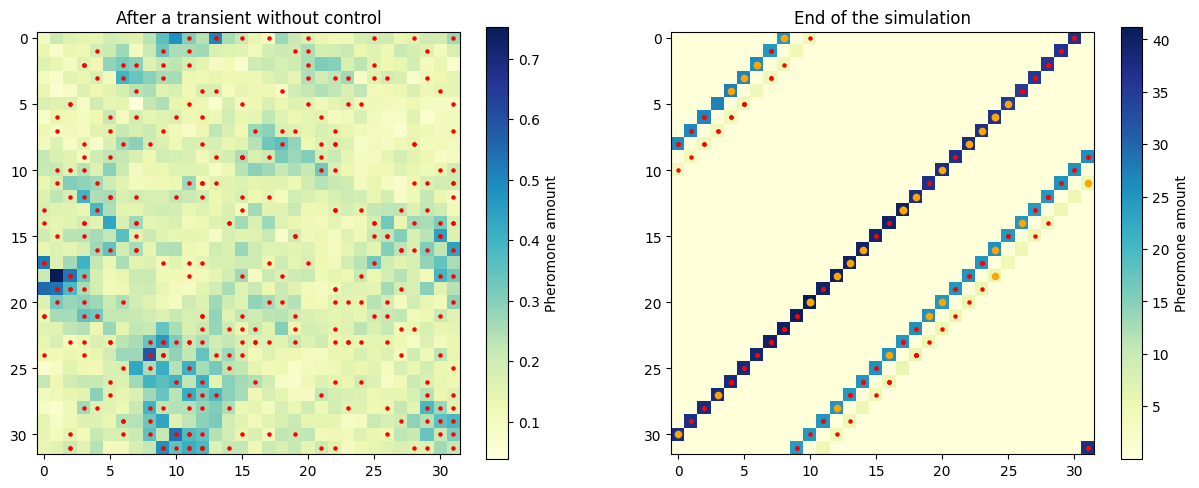

In [14]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1,2,figsize=(15, 8))

im1 = ax[0].imshow(trans_pher, cmap='YlGnBu')
ax[0].scatter(np.array(trans_pos)[:ppo_ants.env.n,1],np.array(trans_pos)[:ppo_ants.env.n,0], c='red', s=5)
ax[0].set_title('After a transient without control')
cbar1 = plt.colorbar(im1, ax=ax[0], shrink=0.7)
cbar1.set_label('Pheromone amount')

im2 = ax[1].imshow(ppo_ants.env.pheromones, cmap='YlGnBu')
ax[1].scatter(np.array(ppo_ants.env.positions)[:ppo_ants.env.n,1],np.array(ppo_ants.env.positions)[:ppo_ants.env.n,0], c='red', s=5)
ax[1].scatter(np.array(ppo_ants.env.positions)[ppo_ants.env.n:,1],np.array(ppo_ants.env.positions)[ppo_ants.env.n:,0], c='orange', s=20)
ax[1].set_title('End of the simulation')

cbar2 = plt.colorbar(im2, ax=ax[1], shrink=0.7)
cbar2.set_label('Pheromone amount')

plt.savefig('trails.pdf')
plt.show()

In [15]:
ppo_ants.env.order_parameter_p()

np.float64(1.0)

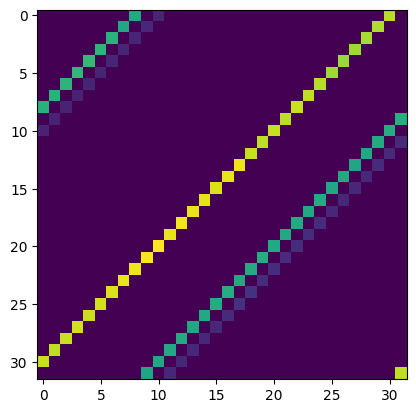

In [16]:
plt.imshow(ppo_ants.env.pheromones)

In [14]:
rewards = np.array(results[0])
actions = np.array(results[1])
states = np.array(results[2])
pos = np.array(results[3])
pher = np.array(results[4])

/tmp/ipykernel_126714/4068522254.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  states = np.array(results[2])


In [18]:
save_for_gif = False

if save_for_gif:
    np.save('pos_list.npy', pos)
    np.save('pher_list.npy', pher)

In [15]:
rewards[-1]

array([-0.46779997, -0.5334934 , -0.50429632, -0.48239851, -0.4605007 ,
       -0.48239851, -0.48239851, -0.48969778, -0.48239851, -0.47509924,
       -0.47509924, -0.47509924, -0.47509924, -0.49699705, -0.46779997,
       -0.48239851, -0.48239851, -0.49699705, -0.50429632, -0.51159559,
       -0.47509924, -0.47509924, -0.4605007 , -0.49699705, -0.48969778,
       -0.4605007 , -0.47509924, -0.46779997, -0.48239851, -0.46779997])

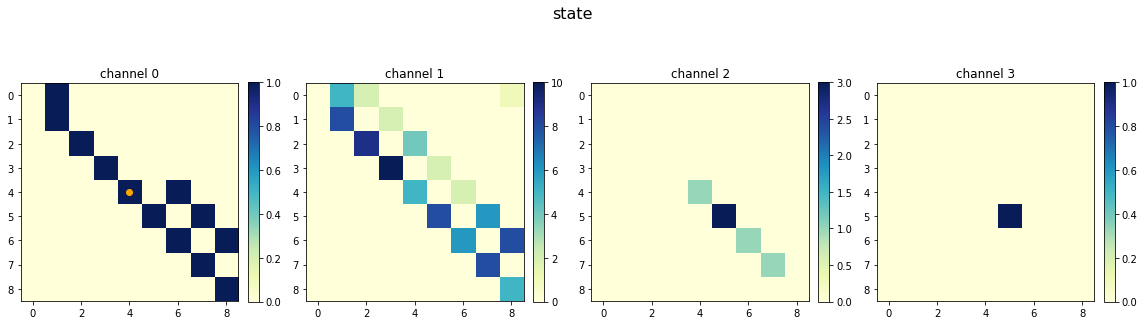

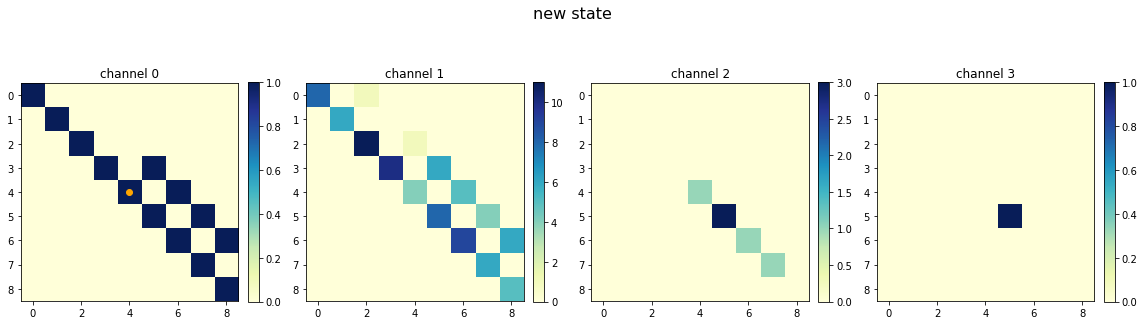

In [ ]:
ind = 3
new_s = states[-ind]
s = states[-(30+ind)]

fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for i in range(4):
    if i == 0:
        im = axs[i].imshow(s[i] > np.mean(s[i]), cmap='YlGnBu')
        # im = axs[i].imshow(s[i] > 2*env.s0, cmap='YlGnBu')
        axs[i].scatter(4,4, c='orange')
    else:
        im = axs[i].imshow(s[i], cmap='YlGnBu')
    axs[i].set_title(f"channel {i}")
    fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)

plt.suptitle("state", fontsize=16)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for i in range(4):
    if i == 0:
        im = axs[i].imshow(new_s[i] > np.mean(new_s[i]), cmap='YlGnBu')
        # im = axs[i].imshow(new_s[i] > 2*env.s0, cmap='YlGnBu')
        axs[i].scatter(4,4, c='orange')
    else:
        im = axs[i].imshow(new_s[i], cmap='YlGnBu')
    axs[i].set_title(f"channel {i}")
    fig.colorbar(im, ax=axs[i], fraction=0.046, pad=0.04)

plt.suptitle("new state", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
ppo_ants.reward(new_s.reshape(1,4,9,9),0)

-0.2771803140640259

In [ ]:
rewards.shape

(1000, 30)

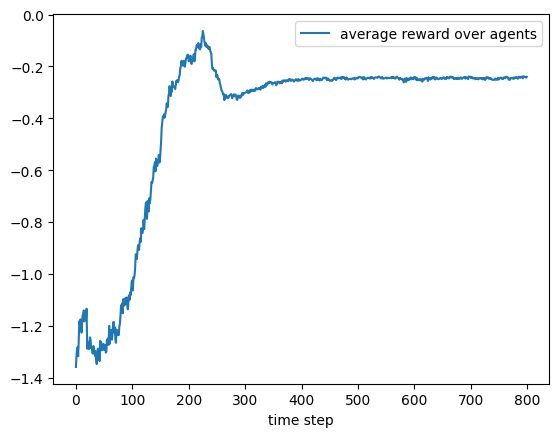

In [19]:
plt.plot(rewards.mean(axis=1), label='average reward over agents')
plt.xlabel('time step')
plt.legend()

In [ ]:
states.shape

(30000, 4, 9, 9)

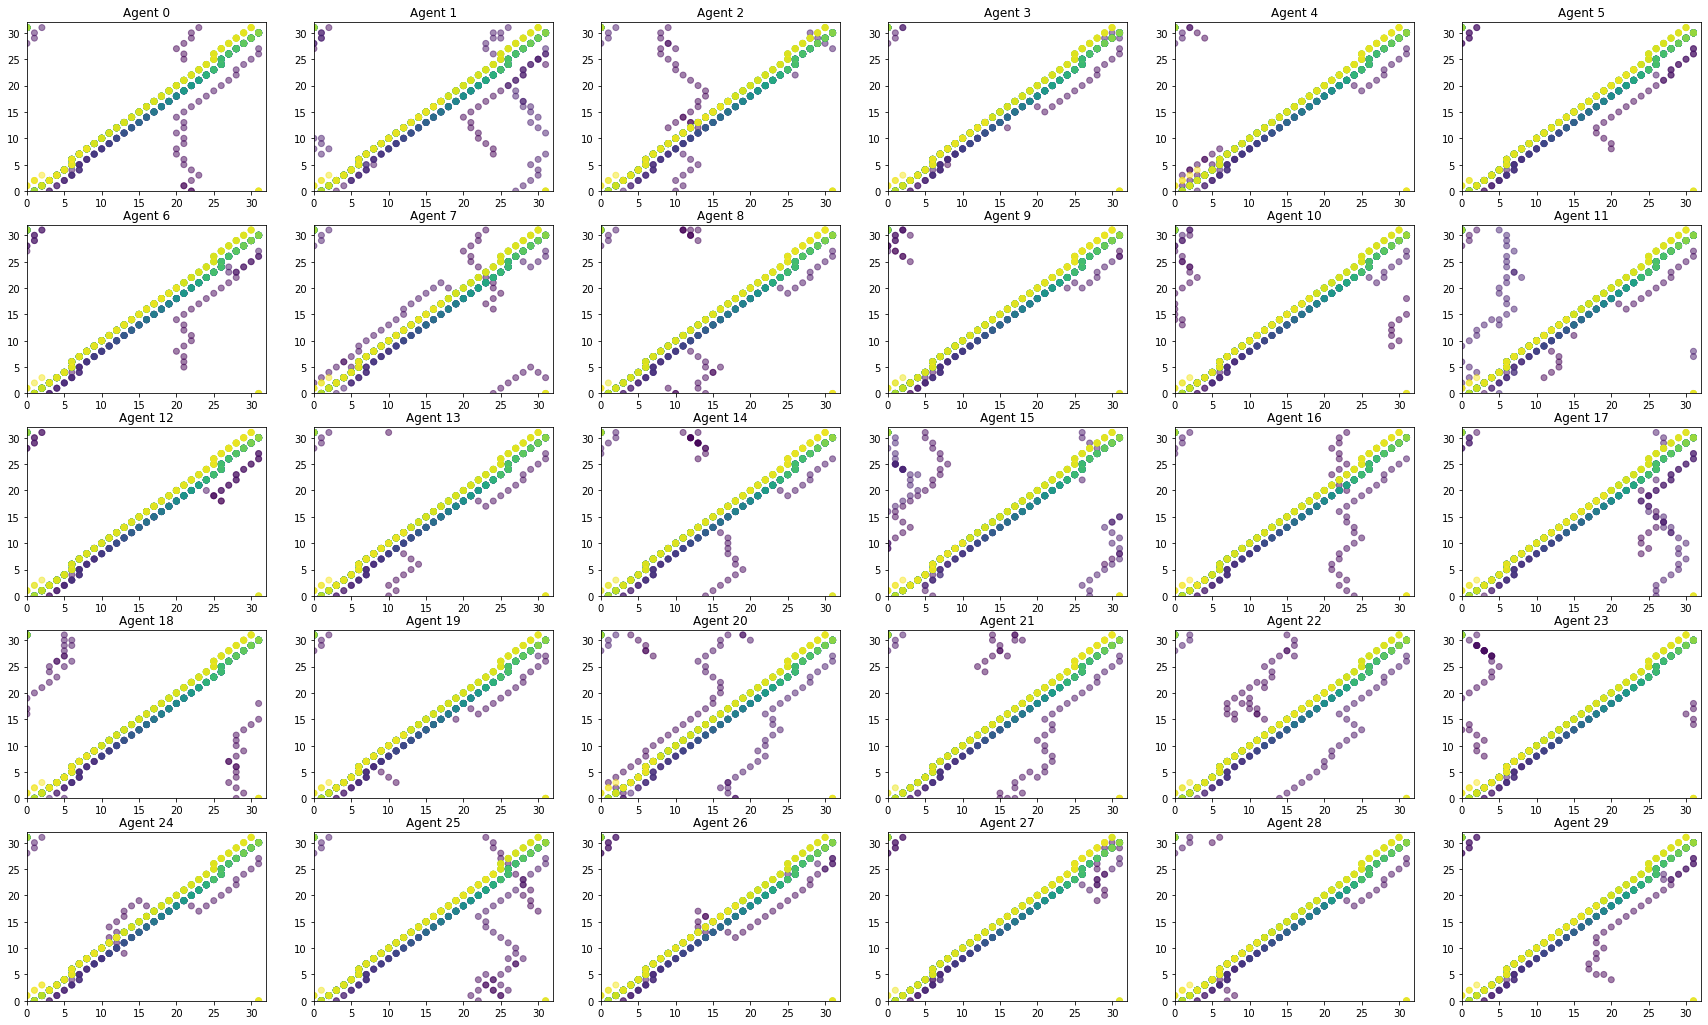

In [ ]:
fig, ax = plt.subplots(5, 6, figsize=(30, 18))
for i in range(5):
    for j in range(6):
        ind = i*6 + j
        ax[i,j].set_title(f"Agent {ind}")
        ax[i,j].scatter(pos[:,env.n+ind,1], pos[:,env.n+ind,0], c=np.arange(tmax-t_transient), alpha=0.5)
        ax[i,j].set_ylim(0, Ly)
        ax[i,j].set_xlim(0, Lx)

plt.show()

In [ ]:
asdfgh

NameError: name 'asdfgh' is not defined

In [ ]:
rewards = np.array(results[0])
actions = np.array(results[1])
states = np.array(results[2])
pos = np.array(results[3])

running = True

pygame.init()

# set the color of the background
background_color = (255, 255, 255) 

# create the screen
screen_x, screen_y = 1000, 1000
screen_scale = screen_x/Lx

screen = pygame.display.set_mode((screen_x, screen_y)) 

# set the frame rate
FPS = 60
clock = pygame.time.Clock()

t = 0   

while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False
    
    # display env 
    screen.fill(background_color)

    for i in range(env.num):
            
        if i < env.n:
            pygame.draw.circle(screen, (0, 0, 0), 
                                (pos[t,i,0]*screen_scale, pos[t,i,1]*screen_scale), 3)
        if i > env.n:
            pygame.draw.circle(screen, (255, 0, 0), 
                                (pos[t,i,0]*screen_scale, pos[t,i,1]*screen_scale), 10)

    # update counter
    t += 1

    if t == (tmax-t_transient):
        running = False

    # env.pheromones[env.t%Lx, env.t%Ly] += power*amount[0]

    # update display
    pygame.display.flip()
    # limit the frame rate
    clock.tick(FPS)

    print(t, end='\r')
    
pygame.quit()

In [ ]:
actions.shape

In [ ]:
plt.hist(actions.flatten(), bins=np.arange(9))

In [ ]:
fake = False

if fake==True:
    fake_env = Ants(300, Lx, Ly, delta, beta, decay_rate, 0.07, 0,
            1000, 0, 0, vision=state_dim[-1])

    for _ in range(1000):
        fake_env.update()
    fake_env.compute_density()
    fake_env.compute_density_spec()

    fake_field = fake_env.pheromones.copy()
    fake_rho = fake_env.rho.copy()
    fake_rho_spec = fake_env.rho_spec.copy()

In [ ]:
test_field = ppo_ants.env.pheromones.copy()
test_rho = ppo_ants.env.rho.copy()
test_rho_spec = ppo_ants.env.rho_spec.copy()
# fake_field = ppo_ants.grid

trial_field = test_field
trial_rho = test_rho
trial_rho_spec = test_rho_spec

if fake == True:
    trial_field = fake_field
    trial_rho = fake_rho
    trial_rho_spec = fake_rho_spec

In [ ]:
# critic evaluation
value_list = []
avg_action_list = []
ppo_ants.critic.eval()

for i in range(env.Lx):
    for j in range(env.Ly):
        s1 = trial_field[ppo_ants.meshgrid(i, j)].reshape(1, vision, vision)
        s2 = trial_rho[ppo_ants.meshgrid(i, j)].reshape(1, vision, vision)
        s3 = trial_rho_spec[ppo_ants.meshgrid(i, j)].reshape(1, vision, vision)
        s4 = np.zeros((1,vision,vision))
        s4[0,vision//2,vision//2] = 1 # prova con tutte le 8 dirs
        
        s = np.concatenate((s1, s2, s3, s4), axis=0)
        s = torch.tensor(s, dtype=torch.float32).unsqueeze(0)
        v = ppo_ants.critic(s).detach().numpy()
        
        value_list.append(v)
        actions = F.softmax(ppo_ants.actor(s).detach(), dim=1).numpy()
        avg_action_list.append(np.sum(env.directions*actions[0,:,np.newaxis], axis=0))

directions = env.directions
field = avg_action_list

In [ ]:
value_grid = np.array(value_list).reshape(env.Lx, env.Ly)
field = np.array(field).reshape(env.Lx, env.Ly, 2)

# Extract coordinates
X, Y = np.meshgrid(np.arange(env.Lx), np.arange(env.Ly))  # Grid positions
U, V = field[:, :, 0], field[:, :, 1]  # Vector components

# Plot the quiver plot
plt.figure(figsize=(8,6))

plt.imshow(trial_field>ppo_ants.k*env.s0, cmap='YlGnBu', alpha=0.5)

plt.quiver(X, Y, V, U, value_grid,  angles='xy', scale_units='xy', scale=2, cmap='viridis')
plt.colorbar(label="Value Function")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Vector Field of Best Actions")
plt.show()

In [ ]:
value_grid = np.array(value_list).reshape(env.Lx, env.Ly)
field = np.array(field).reshape(env.Lx, env.Ly, 2)

# Extract coordinates
X, Y = np.meshgrid(np.arange(env.Lx), np.arange(env.Ly))  # Grid positions
U, V = field[:, :, 0], field[:, :, 1]  # Vector components

# Plot the quiver plot
plt.figure(figsize=(8,6))

plt.imshow(trial_rho, cmap='YlGnBu', alpha=0.5)

plt.quiver(X, Y, V, U, value_grid,  angles='xy', scale_units='xy', scale=1, cmap='viridis')
plt.colorbar(label="Value Function")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Vector Field of Best Actions")
plt.show()

In [ ]:
plt.figure(figsize=(15, 5))
for i in range(ppo_ants.critic.cnn_layers[0].weight.shape[0]):
    plt.subplot(1, ppo_ants.critic.cnn_layers[0].weight.shape[0], i + 1)
    plt.imshow(ppo_ants.critic.cnn_layers[0].weight.data.cpu().numpy()[i, 0, :, :], cmap='viridis')
    plt.axis('off')
    plt.title(f'F{i+1}')
plt.tight_layout()

In [ ]:
plt.figure(figsize=(15, 5))
for i in range(ppo_ants.actor.cnn_layers[0].weight.shape[0]):
    plt.subplot(1, ppo_ants.actor.cnn_layers[0].weight.shape[0], i + 1)
    plt.imshow(ppo_ants.actor.cnn_layers[0].weight.data.cpu().numpy()[i, 0, :, :], cmap='viridis')
    plt.axis('off')
    plt.title(f'F{i+1}')
plt.tight_layout()

In [ ]:
trial_state = np.zeros((1,4,9,9))
for i in range(9):
    for j in range(9):
        if i == j:#and i!=5:
            trial_state[0,0,i,j] = 30
            trial_state[0,1,i,j] = 5

d = [1,1] 
trial_state[0,3,1+d[0],1+d[1]] = 1

In [ ]:
trial_state = np.zeros((1,4,9,9))
ll = 9
for i in range(9):
    if i<4 or i>4:
        pass
    else:
        trial_state[0,0,:ll,i] = np.ones(ll)*10
        trial_state[0,1,:ll,i] = np.ones(ll)*1
        
d = [0,-1] 
trial_state[0,3,4+d[0],4+d[1]] = 1

In [ ]:
trial_state = np.zeros((1,4,9,9))
ll = 5
for i in range(9):
    if i<4 or i>4:
        pass
    else:
        trial_state[0,0,i,:ll] = np.ones(ll)*30
        trial_state[0,1,i,:ll] = np.ones(ll)*5
        
        trial_state[0,0,i,ll+1:] = np.ones(9-ll-1)*30
        trial_state[0,1,i,ll+1:] = np.ones(9-ll-1)*5
        
d = [0,1] 
trial_state[0,3,1+d[0],1+d[1]] = 1

In [ ]:
trial_state = np.zeros((1,4,9,9))
trial_state[0,0] = np.random.uniform(0,10,(9,9))
trial_state[0,1] = np.random.randint(0,1,(9,9))
d = [0,1] 
trial_state[0,3,4+d[0],4+d[1]] = 1

In [ ]:
plt.imshow(trial_state[0,0])
# plt.scatter(4+d[0],4+d[1], c='red')
ppo_ants.critic.eval()
s = torch.tensor(trial_state, dtype=torch.float32)
v = ppo_ants.critic(s).detach().numpy()
a = F.softmax(ppo_ants.actor(s).detach(), dim=1).numpy()
for i in range(8):
    x = env.directions[i, 0] + 4
    y = env.directions[i, 1] + 4
    plt.text(y, x, f"{a[0,i]:.2f}", fontsize=8, ha='center', va='center', color='red')
    
plt.arrow(4, 4, d[1]/5, d[0]/5, head_width=0.3, head_length=0.3, fc='black', ec='black')
    
plt.title(f'value: {v[0,0]:.2f}')
plt.show()

In [ ]:
ppo_ants.reward(trial_state, 0)

In [ ]:
rand = np.random.randint(0,3000)
trial_state = states[rand].copy().reshape(1,4,9,9)

In [ ]:
plt.imshow(trial_state[0,0])
# plt.scatter(4+d[0],4+d[1], c='red')
ppo_ants.critic.eval()
d = np.array(trial_state[0,3].nonzero())-4
s = torch.tensor(trial_state, dtype=torch.float32)
v = ppo_ants.critic(s).detach().numpy()
a = F.softmax(ppo_ants.actor(s).detach(), dim=1).numpy()
for i in range(8):
    x = env.directions[i, 0] + 4
    y = env.directions[i, 1] + 4
    plt.text(y, x, f"{a[0,i]:.2f}", fontsize=8, ha='center', va='center', color='red')
    
plt.arrow(4, 4, d[1,0]/5, d[0,0]/5, head_width=0.3, head_length=0.3, fc='black', ec='black')
    
plt.title(f'value: {v[0,0]:.2f}')
plt.colorbar()
plt.show()

print('reward received: ', rewards[rand//30, rand%30])

In [ ]:
states_per_agent = states.reshape(1000,30,4,9,9)
value_list = []

for i in range(30):
    trial_states = states_per_agent[:, i].copy()
    value_list.append(ppo_ants.critic(torch.tensor(trial_states, dtype=torch.float32)).detach().numpy())

In [ ]:
value_list = np.array(value_list)
plt.figure(figsize=(10, 5))
#for i in range(value_list.shape[0]):
#    plt.plot(value_list[i], label=f'Agent {i}', alpha=0.5)
# plt.plot(value_list[random_index], label=f'Agent {random_index}', alpha=0.5)
plt.plot(value_list.mean(axis=0), label='Average Value Function', color='blue')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Average Value Function Over Time')
#plt.legend()
plt.show()